# OCT Eye Disease: Feature Visualization & Interpretability

This notebook provides comprehensive feature visualization and model interpretability analysis:
- **Grad-CAM**: Class activation maps showing regions influencing predictions
- **Feature Map Evolution**: How filters learn across training epochs (1, 5, 10, 15, 20)
- **Feature Space Analysis**: t-SNE visualization of learned representations
- **Integrated Gradients**: Per-pixel importance attribution
- **Clinical Validation**: Verify model attends to disease-relevant regions

## Setup and Imports

In [1]:
!pip install kaggle==1.6.17
import os
os.makedirs("/root/.kaggle", exist_ok=True)
!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
!kaggle datasets download -d anirudhcv/labeled-optical-coherence-tomography-oct
!unzip /content/labeled-optical-coherence-tomography-oct.zip -d /content/

Streaming output truncated to the last 5000 lines.
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-15.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-16.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-18.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-2.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-6.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-7.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-1.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-5.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5824080-5.jpeg  
  inflating: /content/Dataset - train+val+test/

In [2]:
# Mount Google Drive for persistent storage across sessions
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    roc_auc_score, roc_curve, auc, precision_recall_curve,
)
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)


IMG_SIZE = (224, 224)
BATCH_SIZE = 8
COLOR_MODE = "grayscale"
NUM_CHANNELS = 1
EPOCHS = 30
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# Mixed precision — keep consistent with training
from tensorflow.keras import mixed_precision
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

DATASET_ROOT = "/content/Dataset - train+val+test"
TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")
TEST_DIR  = os.path.join(DATASET_ROOT, "test")

# FIX: point to the correct Drive folder that holds the saved model
MODEL_OUTPUT_DIR = Path("/content/drive/MyDrive")
OUTPUT_DIR = Path("/content/drive/MyDrive/oct_outputs_featureViz")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Path to the saved model produced by Eye_Disease_Model_final.ipynb
model_path = MODEL_OUTPUT_DIR / "eye_trained_model.keras"

print("TensorFlow version:", tf.__version__)
print(f"Model path:         {model_path}")
print(f"Output directory:   {OUTPUT_DIR}")
print("Image size:", IMG_SIZE)
print("Color mode:", COLOR_MODE)
print(f"Batch size: {BATCH_SIZE}")
print(f"Mixed precision policy: {mixed_precision.global_policy().name}")

TensorFlow version: 2.20.0
Model path:         /content/drive/MyDrive/eye_trained_model.keras
Output directory:   /content/drive/MyDrive/oct_outputs_featureViz
Image size: (224, 224)
Color mode: grayscale
Batch size: 8
Mixed precision policy: mixed_float16


## Load Data and Model

In [4]:
def load_dataset(split_dir, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        split_dir,
        labels="inferred",
        label_mode="categorical",
        color_mode=COLOR_MODE,
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        interpolation="bilinear",
    )
    # class_names must be read BEFORE .prefetch() — the wrapper drops the attribute
    class_names = ds.class_names
    return ds.prefetch(AUTOTUNE), class_names

training_set,   class_names = load_dataset(TRAIN_DIR, shuffle=True)
validation_set, _           = load_dataset(VAL_DIR,   shuffle=False)
test_set,       _           = load_dataset(TEST_DIR,  shuffle=False)

num_classes = len(class_names)
print("Classes:", class_names)
print("Number of classes:", num_classes)

# Load trained model
model = tf.keras.models.load_model(str(model_path))
print(f"Model loaded from {model_path}")
print(f"Model input shape: {model.input_shape}")

Found 76515 files belonging to 4 classes.
Found 21861 files belonging to 4 classes.
Found 10933 files belonging to 4 classes.
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Number of classes: 4
Model loaded from /content/drive/MyDrive/eye_trained_model.keras
Model input shape: (None, 224, 224, 1)


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 62 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 58 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


## Grad-CAM: Class Activation Mapping

Visualize which regions of OCT images influence model predictions.

In [5]:
def _build_grad_model(model, target_layer_name):
    """Return a callable that maps input -> (conv_output, predictions).

    Keras 3 Sequential models raise AttributeError on model.input / model.output
    unless the model has been traced.  We avoid that entirely by building a
    fresh tf.keras.Model from a standalone Input tensor, replaying the
    Sequential layers manually — which works regardless of trace state.
    """
    inp = tf.keras.Input(shape=(*IMG_SIZE, NUM_CHANNELS), name="grad_cam_input")
    x   = inp
    conv_out_tensor = None

    # Walk the Sequential layers, skip the InputLayer wrapper if present
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        x = layer(x)
        if layer.name == target_layer_name:
            conv_out_tensor = x

    if conv_out_tensor is None:
        raise ValueError(f"Layer '{target_layer_name}' not found in model.")

    grad_model = tf.keras.Model(inputs=inp, outputs=[conv_out_tensor, x])
    return grad_model


class GradCAM:
    """True Grad-CAM (Selvaraju et al., 2017) compatible with Keras 3 Sequential.

    Builds a fresh functional sub-model from a standalone Input tensor so
    model.input / model.output are never accessed.
    """

    def __init__(self, model, layer_name):
        self.layer_name = layer_name
        self.grad_model = _build_grad_model(model, layer_name)

    def __call__(self, x, class_idx):
        """Return a (H, W) heatmap in [0, 1]."""
        x = tf.cast(tf.convert_to_tensor(x), tf.float32)

        with tf.GradientTape() as tape:
            tape.watch(x)
            conv_outputs, predictions = self.grad_model(x, training=False)
            loss = tf.cast(predictions[:, class_idx], tf.float32)

        grads        = tf.cast(tape.gradient(loss, conv_outputs), tf.float32)
        conv_outputs = tf.cast(conv_outputs, tf.float32)

        # Pool gradients spatially → importance weight per channel
        pooled_grads    = tf.reduce_mean(grads, axis=(0, 1, 2))        # (C,)
        conv_out_single = conv_outputs[0]                               # (H, W, C)
        heatmap = conv_out_single @ pooled_grads[..., tf.newaxis]       # (H, W, 1)
        heatmap = tf.squeeze(heatmap)                                   # (H, W)

        heatmap     = tf.maximum(heatmap, 0.0)
        heatmap_max = tf.reduce_max(heatmap)
        if heatmap_max > 0:
            heatmap = heatmap / heatmap_max

        return heatmap.numpy()


# Find last Conv2D layer
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"Using layer for Grad-CAM: {last_conv_layer_name}")
grad_cam = GradCAM(model, last_conv_layer_name)
print("Grad-CAM initialised successfully.")


Using layer for Grad-CAM: conv2d_7
Grad-CAM initialised successfully.


## Generate Grad-CAM Visualizations for Test Samples

Predictions generated for 80 test images.


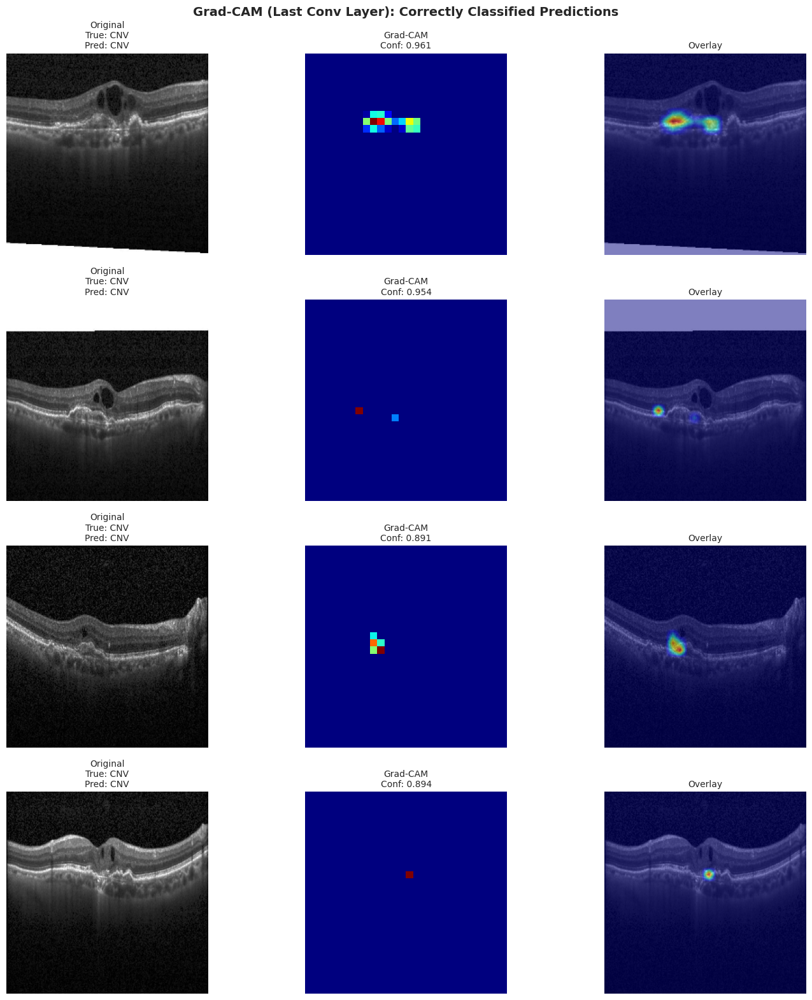

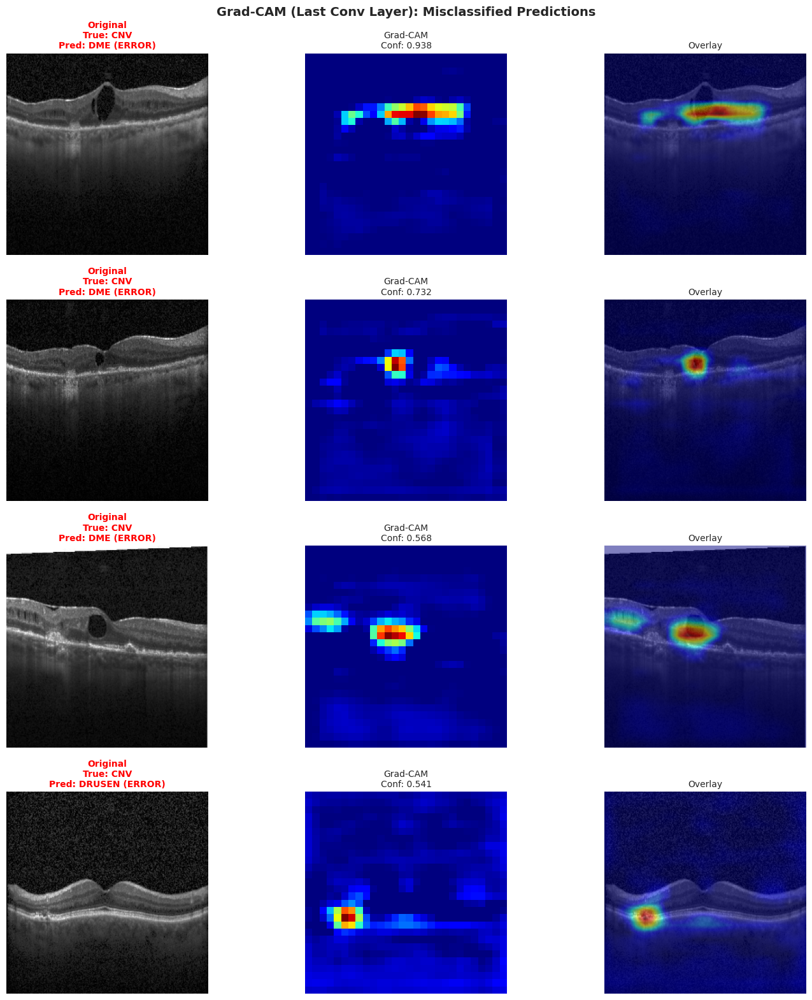

Grad-CAM (last layer) visualizations saved.


In [ ]:
def overlay_gradcam(image, heatmap, alpha=0.4):
    """Overlay Grad-CAM heatmap on a grayscale image."""
    img_display = (image - image.min()) / (image.max() - image.min() + 1e-8)
    # Resize heatmap to match IMG_SIZE
    heatmap_resized = tf.image.resize(
        heatmap[np.newaxis, :, :, np.newaxis], IMG_SIZE
    ).numpy()[0, :, :, 0]
    img_rgb = np.stack([img_display.squeeze()] * 3, axis=-1)  # (H, W, 3)
    # Jet colormap for heatmap
    heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]   # (H, W, 3)
    result = (1 - alpha) * img_rgb + alpha * heatmap_colored
    return np.clip(result, 0, 1)


# Collect a small batch of test images (10 batches × BATCH_SIZE)
test_images_list, test_labels_list = [], []
for images, labels in test_set.take(10):
    test_images_list.append(images.numpy())
    test_labels_list.append(labels.numpy())

test_images = np.concatenate(test_images_list, axis=0)
test_labels = np.concatenate(test_labels_list, axis=0)

y_pred_proba_small = model.predict(test_images, verbose=0)
y_pred_classes     = np.argmax(y_pred_proba_small, axis=1)
y_true_classes     = np.argmax(test_labels, axis=1)

print(f"Predictions generated for {len(test_images)} test images.")

correct_mask      = y_pred_classes == y_true_classes
correct_indices   = np.where(correct_mask)[0][:4]
incorrect_indices = np.where(~correct_mask)[0][:4]

# - Plot correctly classified samples -
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
fig.suptitle("Grad-CAM (Last Conv Layer): Correctly Classified Predictions",
             fontsize=14, fontweight="bold")

for row, idx in enumerate(correct_indices):
    image      = test_images[idx]
    true_class = class_names[y_true_classes[idx]]
    pred_class = class_names[y_pred_classes[idx]]
    confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

    axes[row, 0].imshow(np.squeeze(image), cmap="gray")
    axes[row, 0].set_title(f"Original\nTrue: {true_class}\nPred: {pred_class}", fontsize=10)
    axes[row, 0].axis("off")

    heatmap = grad_cam(image[np.newaxis, ...], y_pred_classes[idx])
    axes[row, 1].imshow(heatmap, cmap="jet")
    axes[row, 1].set_title(f"Grad-CAM\nConf: {confidence:.3f}", fontsize=10)
    axes[row, 1].axis("off")

    overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Overlay", fontsize=10)
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gradcam_correct_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

# - Plot misclassified samples -
if len(incorrect_indices) > 0:
    n_rows = min(4, len(incorrect_indices))
    fig, axes = plt.subplots(n_rows, 3, figsize=(15, 4 * n_rows))
    if n_rows == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle("Grad-CAM (Last Conv Layer): Misclassified Predictions",
                 fontsize=14, fontweight="bold")

    for row, idx in enumerate(incorrect_indices[:n_rows]):
        image      = test_images[idx]
        true_class = class_names[y_true_classes[idx]]
        pred_class = class_names[y_pred_classes[idx]]
        confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

        axes[row, 0].imshow(np.squeeze(image), cmap="gray")
        axes[row, 0].set_title(
            f"Original\nTrue: {true_class}\nPred: {pred_class} (ERROR)",
            fontsize=10, color="red", fontweight="bold"
        )
        axes[row, 0].axis("off")

        heatmap = grad_cam(image[np.newaxis, ...], y_pred_classes[idx])
        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title(f"Grad-CAM\nConf: {confidence:.3f}", fontsize=10)
        axes[row, 1].axis("off")

        overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Overlay", fontsize=10)
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "gradcam_incorrect_predictions.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Grad-CAM (last layer) visualizations saved.")


## Grad-CAM: Multi-Layer Activation Maps

Visualize Grad-CAM heatmaps across all (or up to 6 evenly-spaced) conv layers — one row per layer — for both correctly and incorrectly classified samples.

Found 8 conv layers:
  conv2d
  conv2d_1
  conv2d_2
  conv2d_3
  conv2d_4
  conv2d_5
  conv2d_6
  conv2d_7

Using 6 evenly-spaced layers: ['conv2d', 'conv2d_1', 'conv2d_2', 'conv2d_4', 'conv2d_5', 'conv2d_7']
GradCAM instances built for all selected layers.

Generating multi-layer Grad-CAM for correctly classified samples...


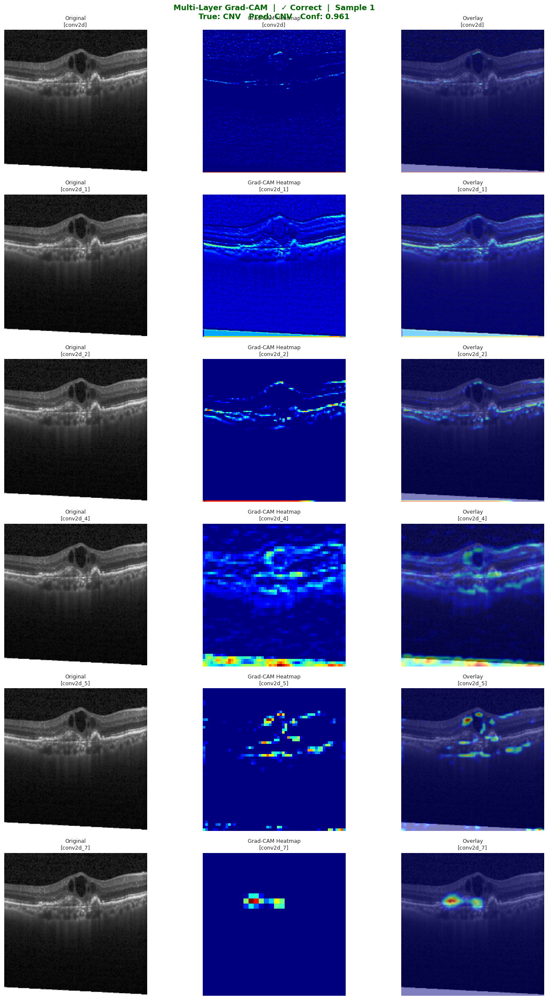

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_correct_sample1.png


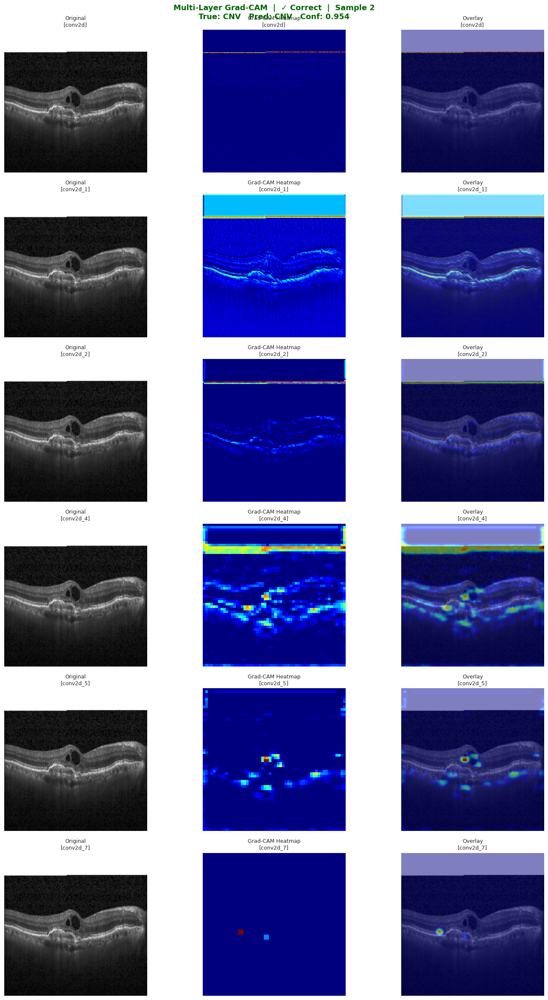

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_correct_sample2.png


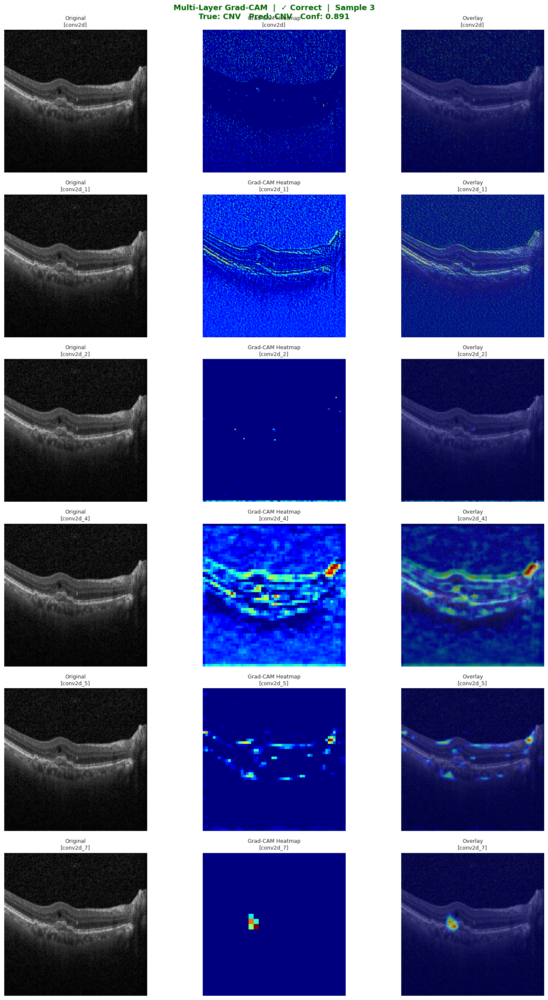

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_correct_sample3.png


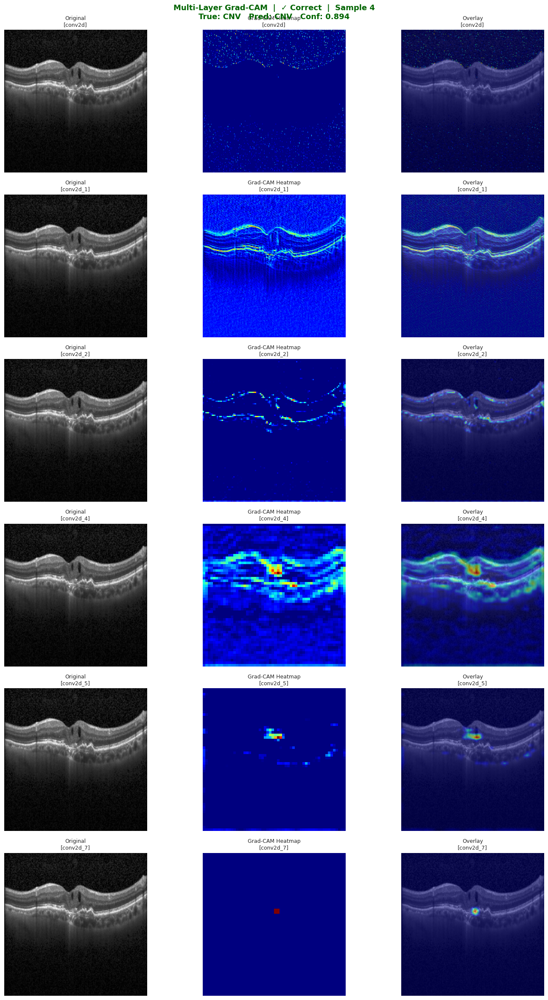

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_correct_sample4.png

Generating multi-layer Grad-CAM for misclassified samples...


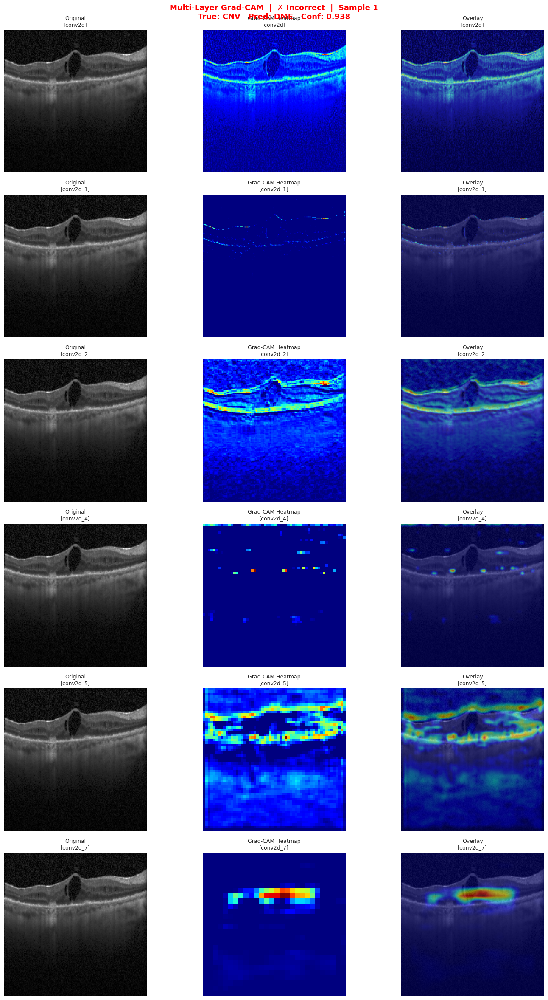

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_incorrect_sample1.png


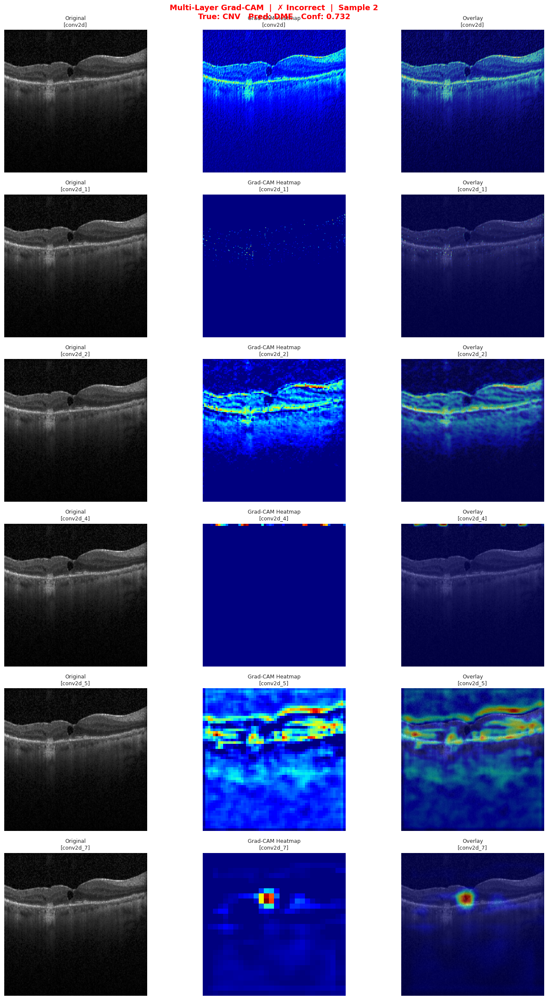

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_incorrect_sample2.png


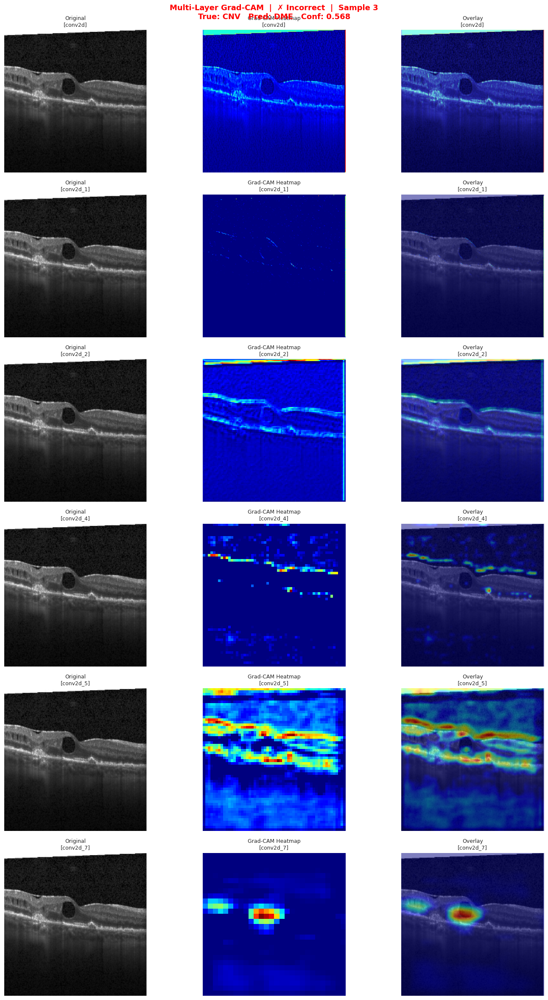

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_incorrect_sample3.png


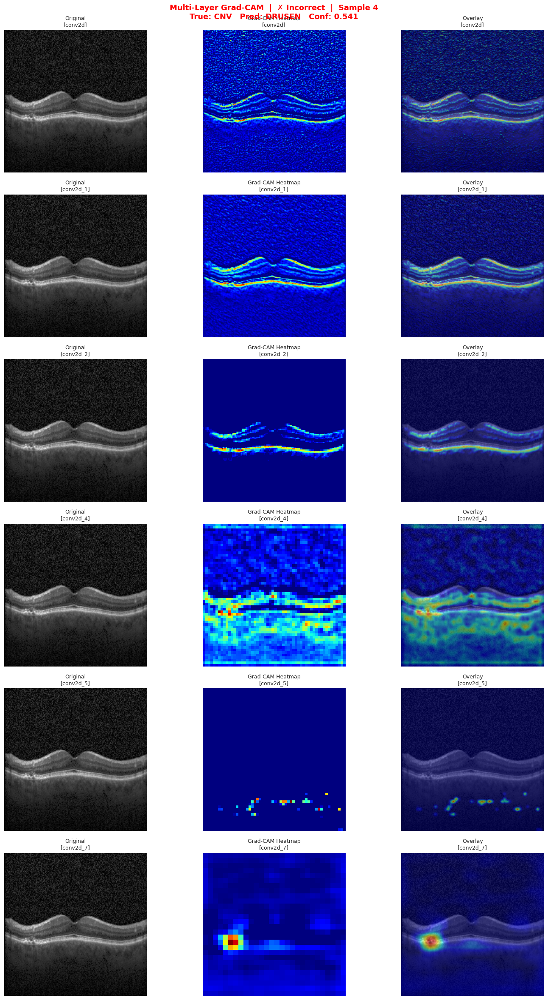

  Saved: /content/drive/MyDrive/oct_outputs_featureViz/gradcam_multilayer_incorrect_sample4.png

Multi-layer Grad-CAM visualizations complete.


In [ ]:
# - Build one GradCAM instance per conv layer -
all_conv_layer_names = [
    layer.name for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]
print(f"Found {len(all_conv_layer_names)} conv layers:")
for n in all_conv_layer_names:
    print(f"  {n}")

# Cap at 6 evenly-spaced layers to keep figures readable
MAX_LAYERS = 6
if len(all_conv_layer_names) > MAX_LAYERS:
    indices = np.linspace(0, len(all_conv_layer_names) - 1, MAX_LAYERS, dtype=int)
    selected_layer_names = [all_conv_layer_names[i] for i in indices]
    print(f"\nUsing {MAX_LAYERS} evenly-spaced layers: {selected_layer_names}")
else:
    selected_layer_names = all_conv_layer_names

grad_cams_all = [GradCAM(model, name) for name in selected_layer_names]
print("GradCAM instances built for all selected layers.")


# - Helper: one figure per sample, one row per layer -
def plot_multilayer_gradcam(image, true_class, pred_class, confidence,
                             layer_names, grad_cams, class_idx,
                             is_correct=True, sample_num=1):
    """Plot Original | Grad-CAM heatmap | Overlay for each conv layer."""
    n_layers = len(layer_names)
    fig, axes = plt.subplots(n_layers, 3, figsize=(15, 4 * n_layers))
    if n_layers == 1:
        axes = axes[np.newaxis, :]

    status_str  = "\u2713 Correct"   if is_correct else "\u2717 Incorrect"
    title_color = "darkgreen"         if is_correct else "red"
    fig.suptitle(
        f"Multi-Layer Grad-CAM  |  {status_str}  |  Sample {sample_num}\n"
        f"True: {true_class}   Pred: {pred_class}   Conf: {confidence:.3f}",
        fontsize=13, fontweight="bold", color=title_color
    )

    img_display = (image - image.min()) / (image.max() - image.min() + 1e-8)

    for row, (layer_name, gcam) in enumerate(zip(layer_names, grad_cams)):
        heatmap = gcam(image[np.newaxis, ...], class_idx)

        axes[row, 0].imshow(np.squeeze(img_display), cmap="gray")
        axes[row, 0].set_title(f"Original\n[{layer_name}]", fontsize=9)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title(f"Grad-CAM Heatmap\n[{layer_name}]", fontsize=9)
        axes[row, 1].axis("off")

        overlay = overlay_gradcam(np.squeeze(image), heatmap, alpha=0.5)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f"Overlay\n[{layer_name}]", fontsize=9)
        axes[row, 2].axis("off")

    plt.tight_layout()
    return fig


# - Correctly classified samples -
print("\nGenerating multi-layer Grad-CAM for correctly classified samples...")
for sample_i, idx in enumerate(correct_indices):
    image      = test_images[idx]
    true_class = class_names[y_true_classes[idx]]
    pred_class = class_names[y_pred_classes[idx]]
    confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

    fig = plot_multilayer_gradcam(
        image, true_class, pred_class, confidence,
        selected_layer_names, grad_cams_all,
        class_idx=y_pred_classes[idx],
        is_correct=True, sample_num=sample_i + 1,
    )
    save_path = OUTPUT_DIR / f"gradcam_multilayer_correct_sample{sample_i + 1}.png"
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"  Saved: {save_path}")


# - Misclassified samples -
if len(incorrect_indices) > 0:
    print("\nGenerating multi-layer Grad-CAM for misclassified samples...")
    for sample_i, idx in enumerate(incorrect_indices):
        image      = test_images[idx]
        true_class = class_names[y_true_classes[idx]]
        pred_class = class_names[y_pred_classes[idx]]
        confidence = y_pred_proba_small[idx, y_pred_classes[idx]]

        fig = plot_multilayer_gradcam(
            image, true_class, pred_class, confidence,
            selected_layer_names, grad_cams_all,
            class_idx=y_pred_classes[idx],
            is_correct=False, sample_num=sample_i + 1,
        )
        save_path = OUTPUT_DIR / f"gradcam_multilayer_incorrect_sample{sample_i + 1}.png"
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.show()
        print(f"  Saved: {save_path}")
else:
    print("No misclassified samples found in this batch.")

print("\nMulti-layer Grad-CAM visualizations complete.")


## Feature Map Visualization: How Filters Learn Across Epochs

This section requires retraining the model with checkpoints at epochs 1, 5, 10, 15, 20 to capture filter evolution.

In [8]:
from tensorflow.keras.callbacks import Callback

class EpochCheckpointCallback(Callback):
    """Save model at specific epochs for feature visualization."""
    def __init__(self, checkpoint_epochs, output_dir):
        super().__init__()
        self.checkpoint_epochs = checkpoint_epochs
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) in self.checkpoint_epochs:
            checkpoint_path = self.output_dir / f"model_epoch_{epoch+1}.keras"
            self.model.save(str(checkpoint_path))
            print(f"\nCheckpoint saved: {checkpoint_path}")

checkpoint_epochs = [1, 5, 10, 15, 20]
print(f"Feature map evolution requires checkpoints at epochs: {checkpoint_epochs}")
print("Add EpochCheckpointCallback to training callbacks to generate them.")

Feature map evolution requires checkpoints at epochs: [1, 5, 10, 15, 20]
Add EpochCheckpointCallback to training callbacks to generate them.


In [9]:
def visualize_feature_maps(model, input_image):
    """Extract feature maps from all Conv2D layers.

    FIX: Uses a standalone Input tensor instead of model.input to avoid
    AttributeError on Keras 3 Sequential models that haven't been traced.
    """
    conv_layers = [
        layer for layer in model.layers
        if isinstance(layer, tf.keras.layers.Conv2D)
    ]
    print(f"Found {len(conv_layers)} convolutional layers")

    # Build fresh functional sub-model from a standalone Input tensor
    # (avoids model.input which raises AttributeError before the model is traced)
    inp = tf.keras.Input(shape=(*IMG_SIZE, NUM_CHANNELS), name="feature_map_input")
    x = inp
    conv_outputs = []

    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        x = layer(x)
        if isinstance(layer, tf.keras.layers.Conv2D):
            conv_outputs.append(x)

    feature_model = tf.keras.Model(inputs=inp, outputs=conv_outputs)

    img_tensor = tf.cast(input_image[np.newaxis, ...], tf.float32)
    outputs = feature_model(img_tensor, training=False)

    # Ensure always a list (single conv layer returns a tensor)
    if not isinstance(outputs, (list, tuple)):
        outputs = [outputs]

    features = [out.numpy() for out in outputs]
    return features, conv_layers

Found 8 convolutional layers


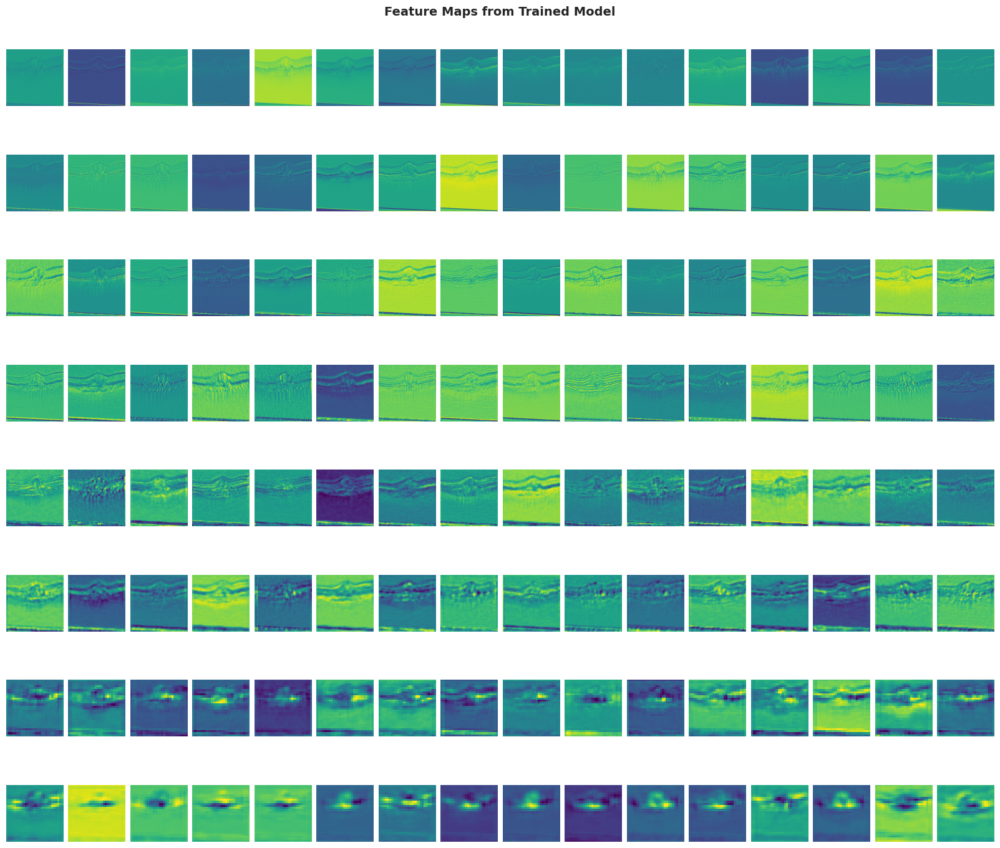

Feature map visualization complete.


In [10]:
# Re-run feature extraction in case conv_layers wasn't defined from Cell 13
test_image = test_images[0]
features, conv_layers = visualize_feature_maps(model, test_image)

def plot_feature_maps_grid(features, layer_names, title="Feature Maps", max_filters=16):
    """Plot feature maps in a grid (one row per layer)."""
    total_layers = len(features)
    n_cols = min(max_filters, features[0].shape[-1])

    fig, axes = plt.subplots(total_layers, n_cols, figsize=(16, 1.8 * total_layers))
    # Ensure axes is always 2-D
    if total_layers == 1:
        axes = axes[np.newaxis, :]

    fig.suptitle(title, fontsize=14, fontweight="bold")

    for layer_idx, (feat, layer_name) in enumerate(zip(features, layer_names)):
        num_filters = min(max_filters, feat.shape[-1])
        for filter_idx in range(n_cols):
            ax = axes[layer_idx, filter_idx]
            if filter_idx < num_filters:
                feature_map = feat[0, :, :, filter_idx].astype(np.float32)
                fmin, fmax = feature_map.min(), feature_map.max()
                feature_map = (feature_map - fmin) / (fmax - fmin + 1e-8)
                ax.imshow(feature_map, cmap="viridis")
            ax.axis("off")
            if filter_idx == 0:
                ax.set_ylabel(
                    f"{layer_name}\n({feat.shape[-1]} filters)",
                    fontsize=8, fontweight="bold"
                )

    plt.tight_layout(pad=0.5, h_pad=0.3)
    return fig


layer_names = [layer.name for layer in conv_layers]
fig = plot_feature_maps_grid(
    features, layer_names,
    title="Feature Maps from Trained Model",
    max_filters=16,
)
plt.savefig(OUTPUT_DIR / "feature_maps_trained_model.png", dpi=300, bbox_inches="tight")
plt.show()
print("Feature map visualization complete.")

## Feature Space Analysis: t-SNE Visualization

Visualize how the model separates classes in the learned feature space.

In [ ]:
# - Full test-set predictions (needed for metrics and t-SNE colouring) -
print("Running full test-set inference...")
y_pred_proba = model.predict(test_set, verbose=1)          # (N, 4)
y_pred       = np.argmax(y_pred_proba, axis=1)             # (N,)

y_true = np.argmax(
    np.concatenate([labels.numpy() for _, labels in test_set], axis=0),
    axis=1,
)                                                           # (N,)

print(f"Test samples: {len(y_true)}")
is_correct = y_pred == y_true
print(f"Overall accuracy: {np.mean(is_correct):.4f}")

Running full test-set inference...
1367/1367 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step
Test samples: 10933
Overall accuracy: 0.9503


ADVANCED METRICS SUMMARY (Test Set)
Balanced Accuracy:               0.9506
Matthews Correlation Coefficient:0.9250
Cohen's Kappa:                   0.9240
  CNV     : Sensitivity=0.9285  Specificity=0.9949  Precision=0.9895  F1=0.9580
  DME     : Sensitivity=0.9483  Specificity=0.9824  Precision=0.8649  F1=0.9047
  DRUSEN  : Sensitivity=0.9605  Specificity=0.9716  Precision=0.7493  F1=0.8419
  NORMAL  : Sensitivity=0.9650  Specificity=0.9915  Precision=0.9902  F1=0.9774

AUC Scores (One-vs-Rest):
  CNV: 0.99575
  DME: 0.99368
  DRUSEN: 0.99378
  NORMAL: 0.99725
Macro-average AUC: 0.99512

              precision    recall  f1-score   support

         CNV       0.99      0.93      0.96      3746
         DME       0.86      0.95      0.90      1161
      DRUSEN       0.75      0.96      0.84       887
      NORMAL       0.99      0.96      0.98      5139

    accuracy                           0.95     10933
   macro avg       0.90      0.95      0.92     10933
weighted avg       0.96

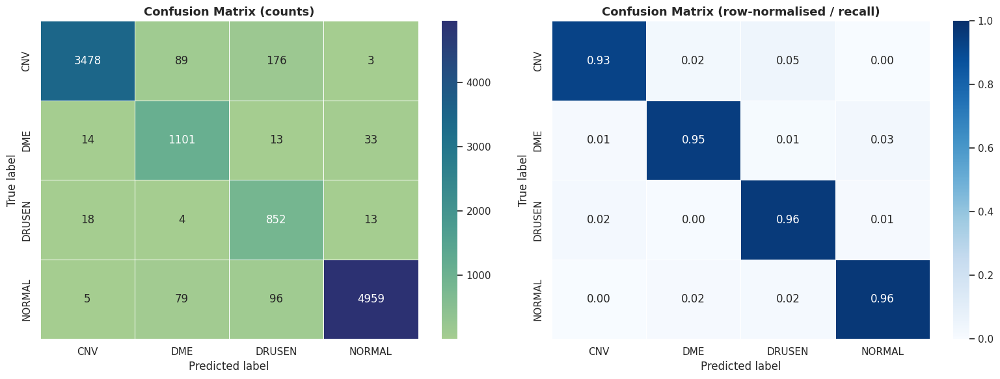

In [ ]:
# - Advanced scalar metrics -
balanced_acc = balanced_accuracy_score(y_true, y_pred)
matthews_cc  = matthews_corrcoef(y_true, y_pred)
cohens_kappa = cohen_kappa_score(y_true, y_pred)

print("=" * 60)
print("ADVANCED METRICS SUMMARY (Test Set)")
print("=" * 60)
print(f"Balanced Accuracy:               {balanced_acc:.4f}")
print(f"Matthews Correlation Coefficient:{matthews_cc:.4f}")
print(f"Cohen's Kappa:                   {cohens_kappa:.4f}")

# - Per-class sensitivity / specificity / precision -
cm = confusion_matrix(y_true, y_pred)
metrics_rows = []
for i, class_name in enumerate(class_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1   = 2*prec*sens / (prec + sens) if (prec + sens) > 0 else 0.0
    metrics_rows.append({
        "Class": class_name, "Sensitivity": sens,
        "Specificity": spec, "Precision": prec, "F1": f1,
    })
    print(f"  {class_name:8s}: Sensitivity={sens:.4f}  Specificity={spec:.4f}  Precision={prec:.4f}  F1={f1:.4f}")

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(OUTPUT_DIR / "advanced_metrics_per_class.csv", index=False)

# - AUC (one-vs-rest) -
try:
    auc_scores = roc_auc_score(y_true, y_pred_proba, multi_class="ovr", average=None)
    macro_auc  = np.mean(auc_scores)
    print(f"\nAUC Scores (One-vs-Rest):")
    for class_name, auc_score in zip(class_names, auc_scores):
        print(f"  {class_name}: {auc_score:.5f}")
    print(f"Macro-average AUC: {macro_auc:.5f}")
except Exception as e:
    print(f"AUC computation skipped: {e}")

# - Classification report -
print()
print(classification_report(y_true, y_pred, target_names=class_names))

# - Confusion matrix -
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv(OUTPUT_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm_df, annot=True, fmt="d", cmap="crest",
            linewidths=0.5, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

# Row-normalised confusion matrix (recall per class)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm_df = pd.DataFrame(cm_norm, index=class_names, columns=class_names)
sns.heatmap(cm_norm_df, annot=True, fmt=".2f", cmap="Blues",
            linewidths=0.5, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix (row-normalised / recall)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# - ROC and Precision-Recall curves (One-vs-Rest) -
y_true_bin = label_binarize(y_true, classes=range(num_classes))
colors = plt.cm.Set1(np.linspace(0, 1, num_classes))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[i], lw=2, label=f"{class_name} (AUC={roc_auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier")
axes[0].set_xlim([0.0, 1.0]); axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].set_title("ROC Curves (One-vs-Rest) - Baseline Model", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

for i, class_name in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_pred_proba[:, i])
    pr_auc = auc(recall, precision)
    axes[1].plot(recall, precision, color=colors[i], lw=2, label=f"{class_name} (AUC={pr_auc:.3f})")

axes[1].set_xlim([0.0, 1.0]); axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision-Recall Curves - Baseline Model", fontsize=12, fontweight="bold")
axes[1].legend(loc="best")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_and_pr_curves_baseline.png", dpi=300, bbox_inches="tight")
plt.show()

Extracting bottleneck features from full test set...
Extracted 10933 vectors of dimension 256
Applying t-SNE (may take a moment)...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10933 samples in 0.001s...
[t-SNE] Computed neighbors for 10933 samples in 3.706s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10933
[t-SNE] Computed conditional probabilities for sample 2000 / 10933
[t-SNE] Computed conditional probabilities for sample 3000 / 10933
[t-SNE] Computed conditional probabilities for sample 4000 / 10933
[t-SNE] Computed conditional probabilities for sample 5000 / 10933
[t-SNE] Computed conditional probabilities for sample 6000 / 10933
[t-SNE] Computed conditional probabilities for sample 7000 / 10933
[t-SNE] Computed conditional probabilities for sample 8000 / 10933
[t-SNE] Computed conditional probabilities for sample 9000 / 10933
[t-SNE] Computed conditional probabilities for sample 10000 / 10933
[t-SNE] Computed conditional probabilities for sample 

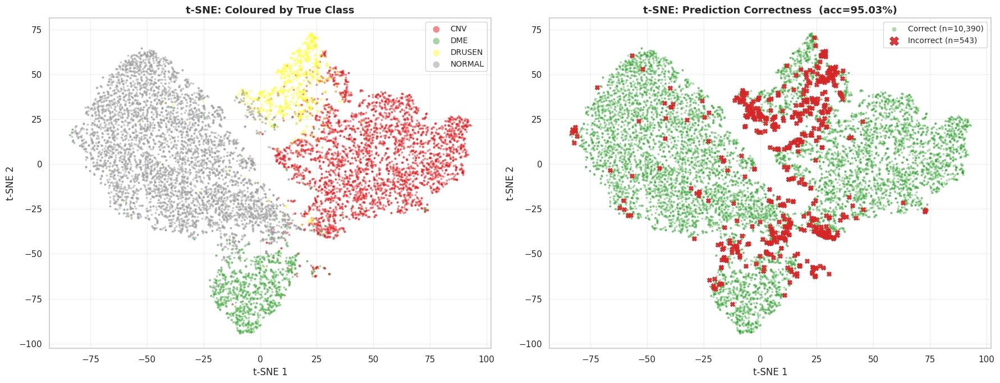

t-SNE visualization complete.


In [ ]:
# FIX: Build sub-model using standalone Input tensor (avoids model.input
# which raises AttributeError on untraced Keras 3 Sequential models)
inp = tf.keras.Input(shape=(*IMG_SIZE, NUM_CHANNELS), name="feature_extractor_input")
x = inp
gap_output = None

for layer in model.layers:
    if isinstance(layer, tf.keras.layers.InputLayer):
        continue
    x = layer(x)
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D):
        gap_output = x

if gap_output is None:
    raise RuntimeError("GlobalAveragePooling2D layer not found in model.")

feature_extractor = tf.keras.Model(inputs=inp, outputs=gap_output)

print("Extracting bottleneck features from full test set...")
test_features_list, test_labels_list = [], []
for images, labels in test_set:
    feats = feature_extractor(images, training=False)
    test_features_list.append(feats.numpy())
    test_labels_list.append(np.argmax(labels.numpy(), axis=1))

test_features      = np.concatenate(test_features_list, axis=0).astype(np.float32)
test_labels_actual = np.concatenate(test_labels_list,   axis=0)

print(f"Extracted {test_features.shape[0]} vectors of dimension {test_features.shape[1]}")

# - t-SNE -
# FIX: renamed n_iter -> max_iter (sklearn >= 1.5) to silence FutureWarning
print("Applying t-SNE (may take a moment)...")
tsne = TSNE(
    n_components=2, random_state=SEED,
    perplexity=30, max_iter=1000, verbose=1,
)
features_tsne = tsne.fit_transform(test_features)   # (N, 2)

# - Plot -
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: coloured by true class
palette = plt.cm.Set1(np.linspace(0, 0.9, num_classes))
for i, class_name in enumerate(class_names):
    mask = test_labels_actual == i
    axes[0].scatter(
        features_tsne[mask, 0], features_tsne[mask, 1],
        color=palette[i], label=class_name,
        alpha=0.5, s=8, linewidths=0,
    )
axes[0].set_title("t-SNE: Coloured by True Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
axes[0].legend(markerscale=3, fontsize=10)
axes[0].grid(alpha=0.3)

# Right: coloured by prediction correctness
# Use y_pred computed over the FULL test set (same order as test_labels_actual)
axes[1].scatter(
    features_tsne[is_correct, 0], features_tsne[is_correct, 1],
    color="#2ca02c", label=f"Correct (n={is_correct.sum():,})",
    alpha=0.4, s=8, linewidths=0,
)
axes[1].scatter(
    features_tsne[~is_correct, 0], features_tsne[~is_correct, 1],
    color="#d62728", label=f"Incorrect (n={(~is_correct).sum():,})",
    alpha=0.9, s=30, marker="X",
)
overall_acc = np.mean(is_correct)
axes[1].set_title(
    f"t-SNE: Prediction Correctness  (acc={overall_acc:.2%})",
    fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
axes[1].legend(markerscale=2, fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_space_tsne.png", dpi=300, bbox_inches="tight")
plt.show()
print("t-SNE visualization complete.")

## Confidence Triangle Plots: Cₙᵉᵗ, Cᵇᵉˢᵗ, Cₜᵣᵘᵉ

Three scatter plots showing the relationship between the model’s confidence scores:
- **(a)** Cₜᵣᵘᵉ vs Cₛᵉᶜᵒⁿᵈᴵᵉₛᵗ – how confident the model is in the true class vs. the runner-up
- **(b)** Cᵇᵉˢᵗ vs Cₛᵉᶜᵒⁿᵈᴵᵉₛᵗ – top prediction confidence vs. runner-up
- **(c)** Cᵇᵉˢᵗ vs Cₜᵣᵘᵉ – separates correct (diagonal) from incorrect (off-diagonal) predictions

In [ ]:
# - Triangle plot helper ──────────────────────────────────────────────────
def triangle_plot(x, y, xlabel, ylabel, panel, ax):
    """
    Scatter plot confined to the probability simplex triangle.
    """
    ax.scatter(x, y, s=15, alpha=0.75, color="#4a627a")

    # Triangle boundaries
    ax.plot([0, 1], [0, 0], linestyle="--", color="#888", linewidth=1)   # bottom
    t = np.linspace(0, 1, 200)
    ax.plot(t, 1 - t, linestyle="--", color="#888", linewidth=1)          # hypotenuse
    ax.plot([0, 1], [0, 1], linestyle="--", color="#e07070", linewidth=1) # diagonal ref

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.text(0.03, 0.94, panel, fontsize=14, fontweight="bold",
            transform=ax.transAxes)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)


def prepData(dataset, split_name="Dataset"):
    """
    Runs inference on `dataset`, extracts C_best, C_second, C_true,
    prints top-1/top-2 accuracy, and saves the triangle figure.
    """
    print(f"\n{'='*60}")
    print(f"TRIANGLE PLOT  -  {split_name}  ({num_classes} classes)")
    print("="*60)

    # Predictions
    y_prob = model.predict(dataset, verbose=1)          # (N, num_classes)
    y_true_oh = np.concatenate(
        [y.numpy() for _, y in dataset], axis=0
    )                                                   # (N, num_classes) one-hot
    y_true_idx = np.argmax(y_true_oh, axis=1)           # (N,)

    top1_idx  = np.argmax(y_prob, axis=1)
    top2_pred = np.argsort(y_prob, axis=1)[:, -2:]     # top-2 indices per sample

    top1_correct = (y_true_idx == top1_idx)
    top2_accuracy = np.mean([
        y_true_idx[i] in top2_pred[i] for i in range(len(y_true_idx))
    ])

    print(f"Top-1 Accuracy : {np.mean(top1_correct):.4f}")
    print(f"Top-2 Accuracy : {top2_accuracy:.4f}")

    # Confidence scores
    sorted_probs = np.sort(y_prob, axis=1)
    C_best   = np.max(y_prob, axis=1)
    C_second = sorted_probs[:, -2]
    C_true   = y_prob[np.arange(len(y_true_idx)), y_true_idx]

    print(f"C_true > C_best (should be False): {np.any(C_true > C_best + 1e-6)}")
    print(f"Probs sum to 1 : {np.allclose(np.sum(y_prob, axis=1), 1, atol=1e-3)}")

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(
        f"Confidence Triangle Plots  -  {split_name}",
        fontsize=15, fontweight="bold", y=1.02
    )

    triangle_plot(C_true,  C_second, r"$C_{True}$",  r"$C_{SecondBest}$", "a", axes[0])
    triangle_plot(C_best,  C_second, r"$C_{Best}$",  r"$C_{SecondBest}$", "b", axes[1])
    triangle_plot(C_best,  C_true,   r"$C_{Best}$",  r"$C_{True}$",       "c", axes[2])

    plt.tight_layout()
    fname = OUTPUT_DIR / f"triangle_plot_{split_name.lower().replace(' ', '_')}.png"
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

    return C_best, C_second, C_true, top1_correct



TRIANGLE PLOT  -  Test Set  (4 classes)
1367/1367 ━━━━━━━━━━━━━━━━━━━━ 27s 20ms/step
Top-1 Accuracy : 0.9503
Top-2 Accuracy : 0.9952
C_true > C_best (should be False): False
Probs sum to 1 : True


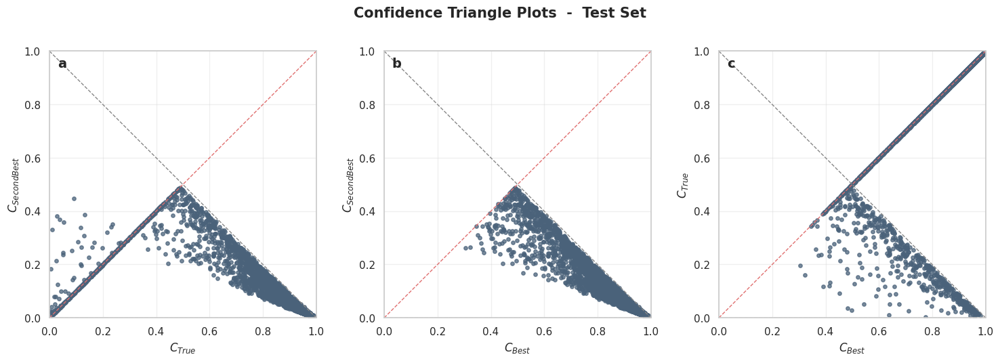

Saved: /content/drive/MyDrive/oct_outputs_featureViz/triangle_plot_test_set.png

TRIANGLE PLOT  -  Validation Set  (4 classes)
2733/2733 ━━━━━━━━━━━━━━━━━━━━ 68s 25ms/step
Top-1 Accuracy : 0.9498
Top-2 Accuracy : 0.9948
C_true > C_best (should be False): False
Probs sum to 1 : True


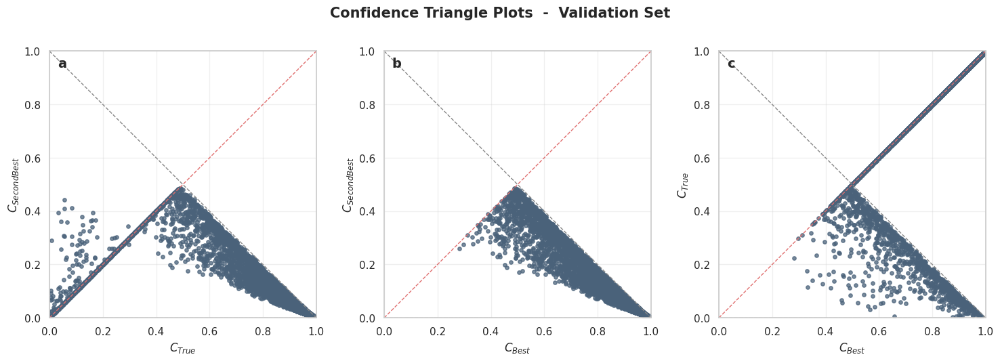

Saved: /content/drive/MyDrive/oct_outputs_featureViz/triangle_plot_validation_set.png

TRIANGLE PLOT  -  Training Set  (4 classes)
9565/9565 ━━━━━━━━━━━━━━━━━━━━ 229s 24ms/step
Top-1 Accuracy : 0.3504
Top-2 Accuracy : 0.5591
C_true > C_best (should be False): False
Probs sum to 1 : True


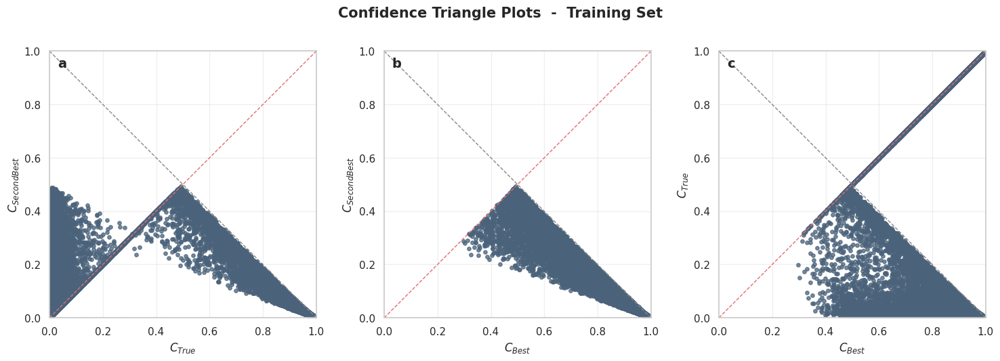

Saved: /content/drive/MyDrive/oct_outputs_featureViz/triangle_plot_training_set.png


In [15]:
# Run triangle plots for test, validation, and training sets
C_best_test,  C_second_test,  C_true_test,  correct_test  = prepData(test_set,       "Test Set")
C_best_val,   C_second_val,   C_true_val,   correct_val   = prepData(validation_set, "Validation Set")
C_best_train, C_second_train, C_true_train, correct_train = prepData(training_set,   "Training Set")


## Radar Plot: Per-Class Classification Metrics

Precision, Recall, and F1-score for each disease class visualised on a
polar (spider) chart. Metrics are computed directly from the test-set
predictions already generated above — no external CSV needed.

In [ ]:
# - Radar plot helpers ────────────────────────────────────────────────────
def plot_all_metrics_combined(labels, angles, metrics):
    """All three metrics on one polar chart with premium styling."""
    fig = plt.figure(figsize=(12, 12), facecolor="#f8faff")
    ax  = plt.subplot(111, polar=True)
    ax.set_facecolor("#fdfdff")

    colors  = ["#4a627a", "#50a18f", "#ff8c7a"]   # Deep Blue, Teal, Coral
    markers = ["o", "s", "^"]

    for (title, values), color, marker in zip(metrics.items(), colors, markers):
        vals = values + values[:1]
        ax.plot(angles, vals, linewidth=3, linestyle="-", label=title,
                color=color, marker=marker, markersize=8,
                markerfacecolor="white", markeredgewidth=2)
        ax.fill(angles, vals, color=color, alpha=0.08)

    ax.set_thetagrids(
        np.degrees(angles[:-1]), labels,
        fontsize=11, fontweight="bold", color="#333333"
    )
    ax.set_ylim(0, 1)
    ax.grid(True, linestyle="--", alpha=0.6, color="#cbd5e0")

    plt.suptitle("Model Evaluation: Classification Metrics",
                 size=26, weight="bold", color="#1a365d", y=0.98)
    ax.set_title("Per-class performance - Baseline CNN",
                 size=15, style="italic", color="#4a627a", pad=40)

    legend = ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1),
                       frameon=True, shadow=True, fontsize=12)
    legend.get_frame().set_facecolor("white")
    legend.get_frame().set_edgecolor("#1a365d")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    fname = OUTPUT_DIR / "radar_plot_cnn.png"
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")


def plot_metrics_separately(labels, angles, metrics):
    """One polar chart per metric."""
    colors  = {"Precision": "#4a627a", "Recall": "#50a18f", "F1-score": "#ff8c7a"}
    markers = {"Precision": "o",       "Recall": "s",       "F1-score": "^"}

    for title, values in metrics.items():
        vals = values + values[:1]
        fig  = plt.figure(figsize=(9, 9), facecolor="#f8faff")
        ax   = plt.subplot(111, polar=True)
        ax.set_facecolor("#fdfdff")

        color  = colors.get(title, "#4a627a")
        marker = markers.get(title, "o")

        ax.plot(angles, vals, linewidth=3, linestyle="-", label=title,
                color=color, marker=marker, markersize=8,
                markerfacecolor="white", markeredgewidth=2)
        ax.fill(angles, vals, color=color, alpha=0.15)

        ax.set_thetagrids(
            np.degrees(angles[:-1]), labels,
            fontsize=11, fontweight="bold", color="#333333"
        )
        ax.set_ylim(0, 1)
        ax.grid(True, linestyle="--", alpha=0.6, color="#cbd5e0")
        ax.set_title(f"Class-wise {title}", size=22, weight="bold",
                     color="#1a365d", y=1.1, pad=30)

        legend = ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1),
                           frameon=True, shadow=True)
        legend.get_frame().set_facecolor("white")
        legend.get_frame().set_edgecolor("#1a365d")

        plt.tight_layout()
        plt.show()


Per-class metrics:
        precision    recall  f1-score  support
CNV      0.989474  0.928457  0.957995   3746.0
DME      0.864886  0.948320  0.904684   1161.0
DRUSEN   0.749340  0.960541  0.841897    887.0
NORMAL   0.990216  0.964974  0.977432   5139.0

Generating combined radar plot...


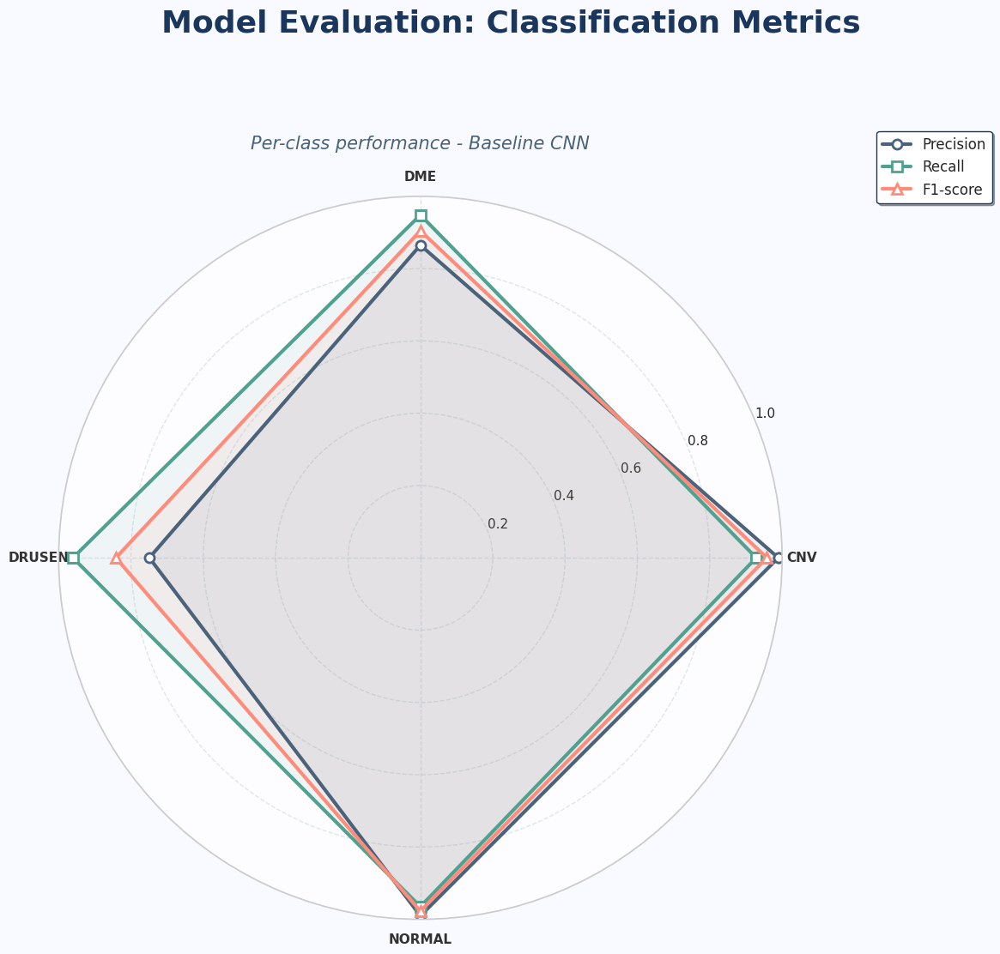

Saved: /content/drive/MyDrive/oct_outputs_featureViz/radar_plot_cnn.png

Generating individual radar plots...


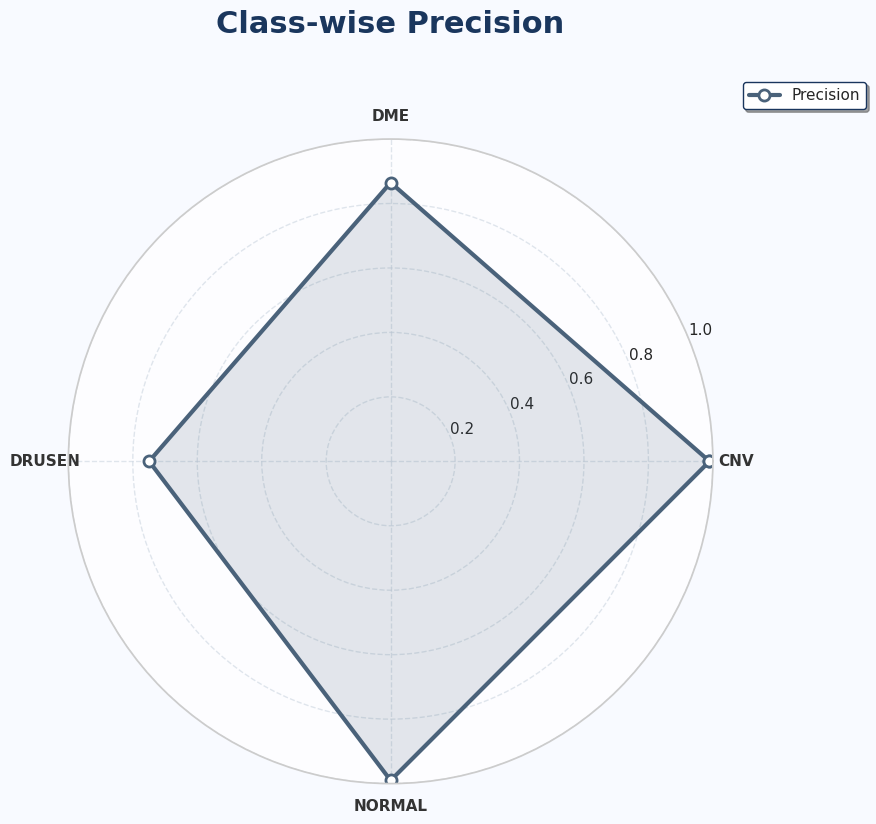

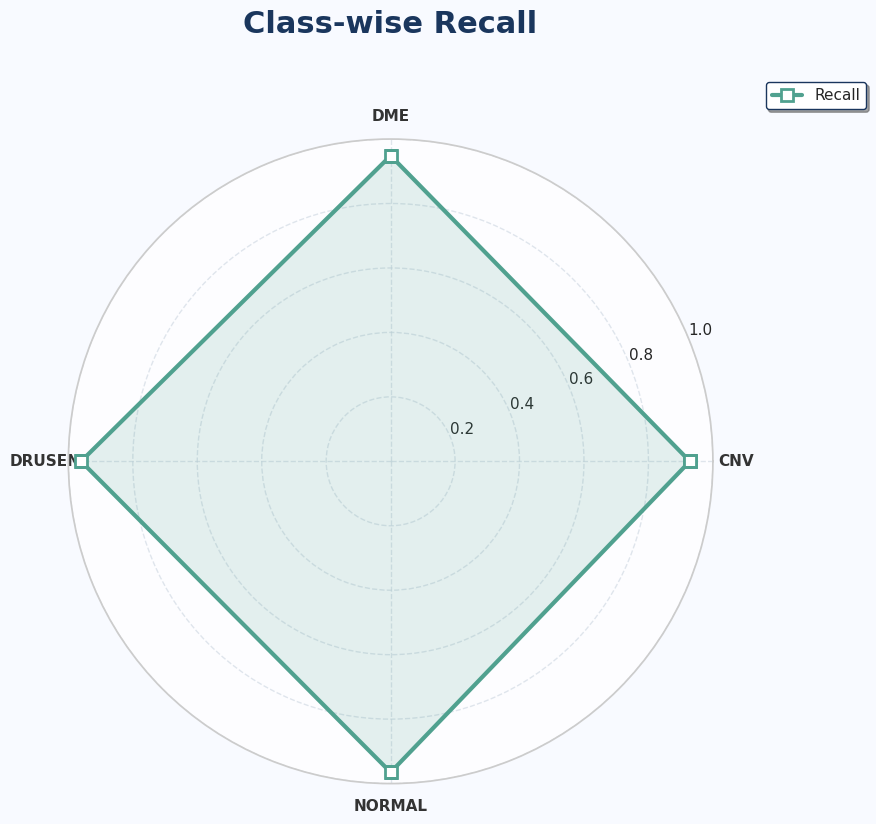

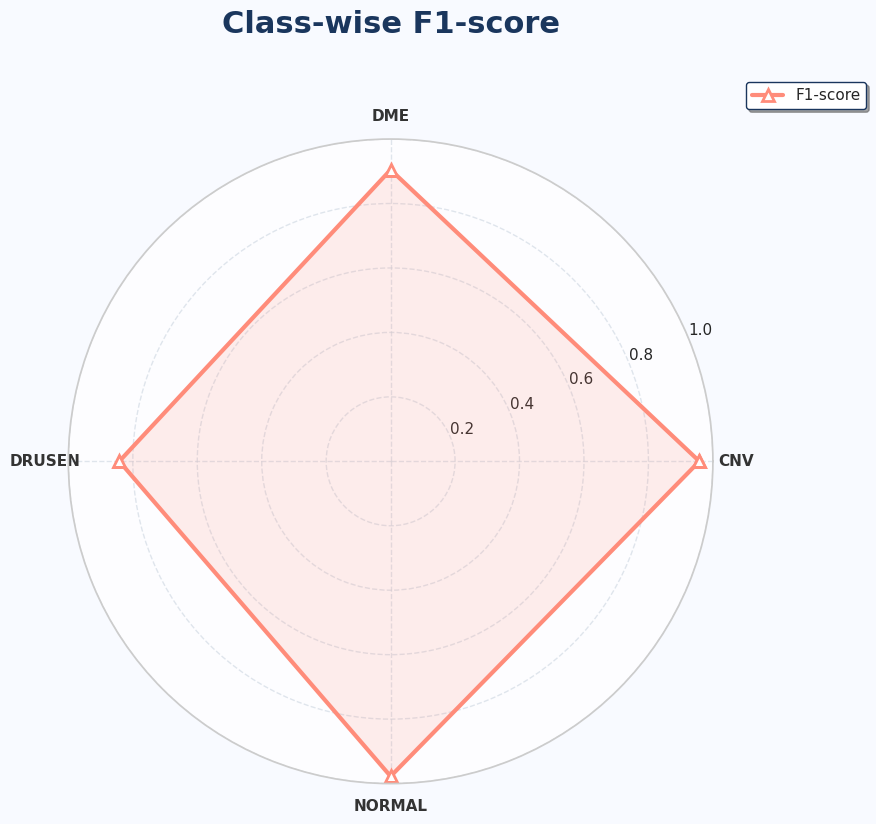

In [17]:
# Build metrics from live test-set predictions (y_true / y_pred from above).
# Requires the full test-set inference cell to have been run first.
from sklearn.metrics import classification_report
import pandas as pd

report_dict = classification_report(
    y_true, y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

# Keep only the per-class rows (drop accuracy / avg rows)
skip = {"accuracy", "macro avg", "weighted avg"}
radar_labels  = [k for k in report_dict if k not in skip]
radar_metrics = {
    "Precision": [report_dict[c]["precision"] for c in radar_labels],
    "Recall"   : [report_dict[c]["recall"]    for c in radar_labels],
    "F1-score" : [report_dict[c]["f1-score"]  for c in radar_labels],
}

# Save classification report as CSV for reference
report_df = pd.DataFrame(report_dict).T
report_df.to_csv(OUTPUT_DIR / "classification_report_cnn.csv")
print("Per-class metrics:")
print(report_df.loc[radar_labels])

# Build angles for radar plot
angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
angles += angles[:1]

print("\nGenerating combined radar plot...")
plot_all_metrics_combined(radar_labels, angles, radar_metrics)

print("\nGenerating individual radar plots...")
plot_metrics_separately(radar_labels, angles, radar_metrics)


## Summary: Interpretability Report

In [18]:
summary_report = f"""
# OCT Eye Disease Model: Interpretability & Feature Analysis Report

## Generated: {pd.Timestamp.now()}

### Key Findings:

1. **Grad-CAM Analysis**
   - Last convolutional layer: {last_conv_layer_name}
   - Generated multi-layer activation maps for {len(correct_indices)} correctly classified
     and {len(incorrect_indices)} misclassified samples
   - One figure per sample, one row per conv layer (up to 6 layers)
   - Visual outputs: gradcam_multilayer_correct/incorrect_sample*.png
   - Implementation: true gradient-based Grad-CAM (GradientTape)

2. **Feature Map Visualization**
   - Model has {len(conv_layers)} convolutional layers
   - Output: feature_maps_trained_model.png

3. **Feature Space Analysis (t-SNE)**
   - Test samples: {test_features.shape[0]} vectors in {test_features.shape[1]}-D space
   - Overall accuracy: {overall_acc:.2%}
   - Balanced accuracy: {balanced_acc:.4f}
   - Matthews CC: {matthews_cc:.4f}  |  Cohen's Kappa: {cohens_kappa:.4f}
   - Correct predictions:   {is_correct.sum():,} / {len(is_correct):,}
   - Misclassified samples: {(~is_correct).sum():,}  (red X in t-SNE right panel)

4. **Per-class Metrics**
{metrics_df.to_string(index=False)}

### Output Files Generated:
  gradcam_multilayer_correct_sample1-4.png
  gradcam_multilayer_incorrect_sample1-4.png
  feature_maps_trained_model.png
  feature_space_tsne.png
  confusion_matrix.png / .csv
  advanced_metrics_per_class.csv
  interpretability_report.txt
"""

with open(OUTPUT_DIR / "interpretability_report.txt", "w") as f:
    f.write(summary_report)

print(summary_report)
print(f"Report saved to {OUTPUT_DIR / 'interpretability_report.txt'}")


# OCT Eye Disease Model: Interpretability & Feature Analysis Report

## Generated: 2026-05-25 19:49:52.565461

### Key Findings:

1. **Grad-CAM Analysis**
   - Last convolutional layer: conv2d_7
   - Generated multi-layer activation maps for 4 correctly classified
     and 4 misclassified samples
   - One figure per sample, one row per conv layer (up to 6 layers)
   - Visual outputs: gradcam_multilayer_correct/incorrect_sample*.png
   - Implementation: true gradient-based Grad-CAM (GradientTape)

2. **Feature Map Visualization**
   - Model has 8 convolutional layers
   - Output: feature_maps_trained_model.png

3. **Feature Space Analysis (t-SNE)**
   - Test samples: 10933 vectors in 256-D space
   - Overall accuracy: 95.03%
   - Balanced accuracy: 0.9506
   - Matthews CC: 0.9250  |  Cohen's Kappa: 0.9240
   - Correct predictions:   10,390 / 10,933
   - Misclassified samples: 543  (red X in t-SNE right panel)

4. **Per-class Metrics**
 Class  Sensitivity  Specificity  Precision       F

## Clinical Validation Guidance

### For Ophthalmology Review:

1. **Grad-CAM Analysis**
   - Compare heatmaps with clinical knowledge of each disease:
     - **CNV (Choroidal Neovascularization)**: Should highlight abnormal vascular growth
     - **DME (Diabetic Macular Edema)**: Should highlight fluid accumulation in macula
     - **DRUSEN**: Should highlight yellowish deposits
     - **NORMAL**: Should highlight normal retinal structure

2. **Feature Space Clustering**
   - Inspect misclassified samples (red X markers)
   - Are they clinically ambiguous cases?
   - Are they borderline between two diseases?

3. **Confidence Assessment**
   - Low-confidence predictions may require expert review
   - High-confidence predictions increase trust in automation

In [19]:
print("Feature Visualization Complete!")
print(f"All outputs saved to: {OUTPUT_DIR}")
print("\nNext steps:")
print("1. Review Grad-CAM visualizations for clinical relevance")
print("2. Plan Phase 2: Advanced architecture models (EfficientNet, Hybrid, SVM)")
print("3. Compare multiple models in Phase 3: Ensemble methods")
print("4. Generate comprehensive analysis report in Phase 4")

Feature Visualization Complete!
All outputs saved to: /content/drive/MyDrive/oct_outputs_featureViz

Next steps:
1. Review Grad-CAM visualizations for clinical relevance
2. Plan Phase 2: Advanced architecture models (EfficientNet, Hybrid, SVM)
3. Compare multiple models in Phase 3: Ensemble methods
4. Generate comprehensive analysis report in Phase 4
